# 03. Feature Engineering & Target Construction
## Rheumatoid Arthritis Classification System

### Executive Purpose
This notebook constructs the standardized, leak-free feature matrix and binary target for the classification system:
1. **Target Engineering**: Constructs `Target_RA` where $1 = \text{Rheumatoid Arthritis}$ and $0 = \text{Non-RA (all 6 other cohorts combined)}$.
2. **Class Verification**: Confirms exact cohort sizes (RA: 2,848; Non-RA: 9,237; Total: 12,085).
3. **Candidate Input Features (14)**:
   - Demographic: `Age`, `Gender`
   - Numeric Laboratory Tests: `ESR`, `CRP`, `RF`, `Anti-CCP`, `C3`, `C4`
   - Categorical Serology: `HLA-B27`, `ANA`, `Anti-Ro`, `Anti-La`, `Anti-dsDNA`, `Anti-Sm`
4. **Leakage Elimination**: Retains `Disease` for clinical audit and traceability, while explicitly separating it from model input features.
5. **Deterministic Row Tracking**: Adds `patient_row_id` for immutable tracking across train/test splits.
6. **Data Export**: Saves the engineered dataset to `data/processed/ra_engineered_dataset.csv`.


In [1]:
import sys
import os
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['figure.figsize'] = (10, 5)

root = Path("..").resolve() if Path("..").resolve().name == "RA_Project" else Path(".").resolve()
if str(root) not in sys.path:
    sys.path.insert(0, str(root))

from src.feature_engineering import (
    validate_raw_data,
    standardize_data,
    create_engineered_features,
    save_engineered_dataset,
    FEATURE_COLUMNS,
    NUMERIC_FEATURES,
    CATEGORICAL_FEATURES,
    TARGET_COLUMN,
    ID_COLUMN,
    TRACE_COLUMN
)

print(f"Project root: {root}")


Project root: D:\PRJ 1 Sem 5\RA_Project


## 1. Raw Ingestion & Schema Validation
We load the raw Excel workbook and validate its schema against expected dimensions and class counts.


In [2]:
raw_excel_path = root / "data" / "raw" / "Rheumatic and Autoimmune Disease Dataset.xlsx"
df_raw = pd.read_excel(raw_excel_path)
print(f"Loaded raw data: {df_raw.shape[0]:,} rows × {df_raw.shape[1]} columns")

# Validate raw data schema
validate_raw_data(df_raw)
print("Raw schema validation passed.")


Loaded raw data: 12,085 rows × 15 columns
Raw schema validation passed.


## 2. Target Formulation (`Target_RA`)
We map `Disease == 'Rheumatoid Arthritis'` to `1` (Positive), and all other six conditions to `0` (Negative).


In [3]:
df_engineered = create_engineered_features(df_raw)

print(f"Engineered Dataset Shape: {df_engineered.shape[0]:,} rows × {df_engineered.shape[1]} columns")
print("\nTarget_RA Distribution:")
target_counts = df_engineered['Target_RA'].value_counts()
target_pct = df_engineered['Target_RA'].value_counts(normalize=True) * 100

target_summary = pd.DataFrame({
    'Count': target_counts,
    'Percentage (%)': target_pct.round(2),
    'Clinical Meaning': ['Non-RA (6 comparison cohorts)', 'Rheumatoid Arthritis']
}, index=[0, 1])
display(target_summary)

# Assertions
assert target_counts[1] == 2848, f"Expected 2848 RA cases, got {target_counts[1]}"
assert target_counts[0] == 9237, f"Expected 9237 Non-RA cases, got {target_counts[0]}"
assert df_engineered['Target_RA'].isnull().sum() == 0, "Null values found in Target_RA!"
print("Target counts and binary integrity verified.")


Engineered Dataset Shape: 12,085 rows × 17 columns

Target_RA Distribution:


,Count,Percentage (%),Clinical Meaning
0,9237,76.43,Non-RA (6 comparison cohorts)
1,2848,23.57,Rheumatoid Arthritis


Target counts and binary integrity verified.


## 3. Cohort Composition & Non-RA Decomposition
We visualize the binary target balance and decompose the Non-RA class across its constituent autoimmune diseases.


C:\Users\anjan\AppData\Local\Temp\ipykernel_22212\2723912337.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=['Non-RA (0)', 'Rheumatoid Arthritis (1)'], y=[target_counts[0], target_counts[1]], palette=colors, ax=axes[0])
C:\Users\anjan\AppData\Local\Temp\ipykernel_22212\2723912337.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=non_ra_dist.values, y=non_ra_dist.index, palette="mako", ax=axes[1])


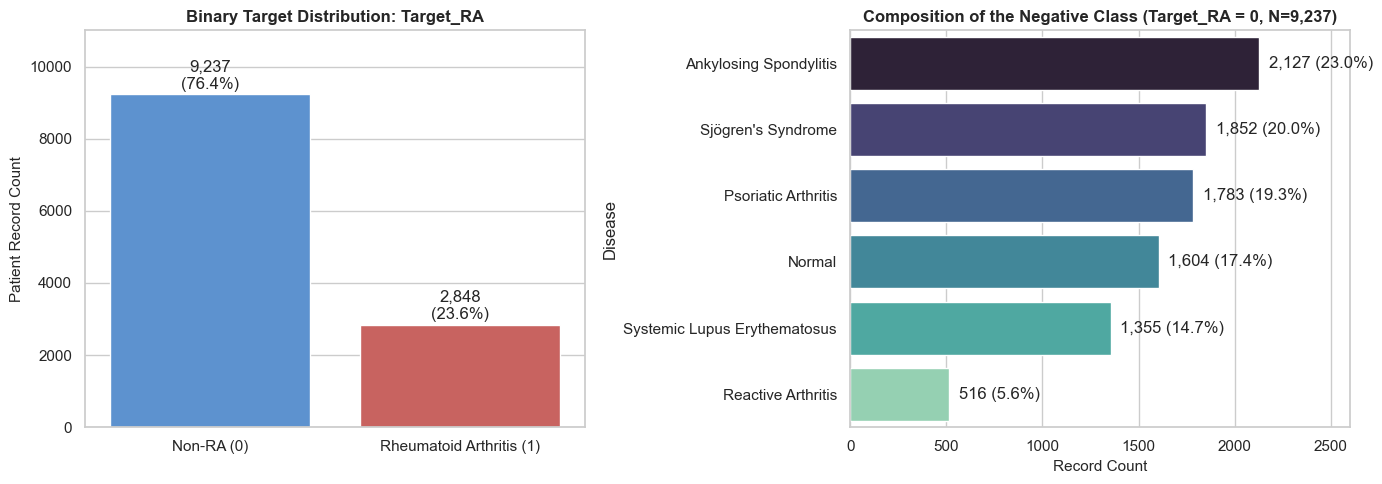

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Binary Target Distribution
colors = ['#4a90e2', '#d9534f']
sns.barplot(x=['Non-RA (0)', 'Rheumatoid Arthritis (1)'], y=[target_counts[0], target_counts[1]], palette=colors, ax=axes[0])
axes[0].set_title("Binary Target Distribution: Target_RA", fontsize=12, fontweight='bold')
axes[0].set_ylabel("Patient Record Count", fontsize=11)
for i, count in enumerate([target_counts[0], target_counts[1]]):
    pct = (count / len(df_engineered)) * 100
    axes[0].text(i, count + 150, f"{count:,}\n({pct:.1f}%)", ha='center', fontweight='medium')
axes[0].set_ylim(0, 11000)

# Plot 2: Non-RA Class Decomposition by Original Diagnosis
non_ra_df = df_engineered[df_engineered['Target_RA'] == 0]
non_ra_dist = non_ra_df['Disease'].value_counts()
sns.barplot(x=non_ra_dist.values, y=non_ra_dist.index, palette="mako", ax=axes[1])
axes[1].set_title("Composition of the Negative Class (Target_RA = 0, N=9,237)", fontsize=12, fontweight='bold')
axes[1].set_xlabel("Record Count", fontsize=11)
for i, v in enumerate(non_ra_dist.values):
    pct = (v / len(non_ra_df)) * 100
    axes[1].text(v + 50, i, f"{v:,} ({pct:.1f}%)", va='center')
axes[1].set_xlim(0, 2600)

plt.tight_layout()
plt.show()


## 4. Clinical Laboratory Biomarker Profiles by Target Class
We examine hallmark serological and inflammatory markers (`RF`, `Anti-CCP`, `ESR`, `CRP`) stratified by `Target_RA`.


C:\Users\anjan\AppData\Local\Temp\ipykernel_22212\2056147460.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_engineered, x='Target_RA', y=col, palette=['#4a90e2', '#d9534f'], ax=ax)
C:\Users\anjan\AppData\Local\Temp\ipykernel_22212\2056147460.py:11: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(['Non-RA (0)', 'RA (1)'])
C:\Users\anjan\AppData\Local\Temp\ipykernel_22212\2056147460.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_engineered, x='Target_RA', y=col, palette=['#4a90e2', '#d9534f'], ax=ax)
C:\Users\anjan\AppData\Local\Temp\ipykernel_22212\2056147460.py:1

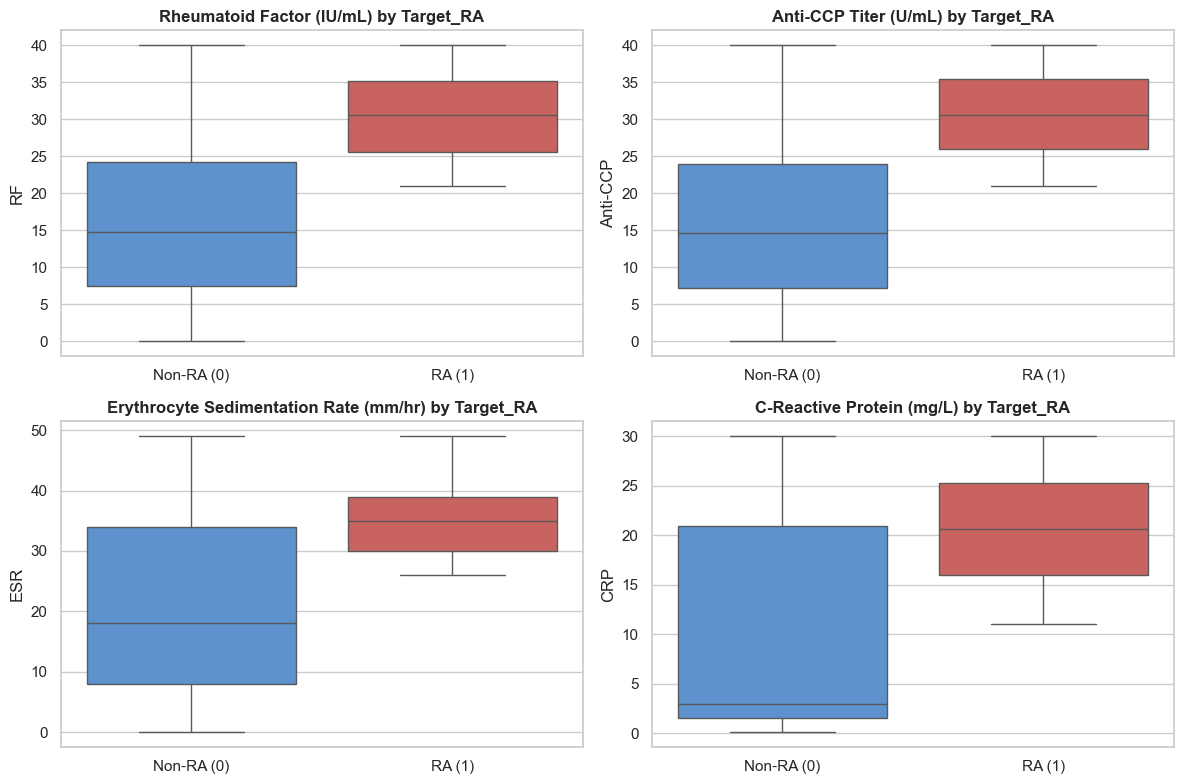

Key Biomarker Summary by Target_RA:


RF               Anti-CCP                 ESR                \
          count median   mean    count median   mean count median   mean   
Target_RA                                                                  
0          8211   14.7  16.37     6781   14.6  16.27  8400   18.0  20.85   
1          2545   30.5  30.37     2041   30.5  30.58  2597   35.0  35.09   

            CRP                  C3                   C4                
          count median   mean count median    mean count median   mean  
Target_RA                                                               
0          7399    2.9  11.09  7932  130.0  128.80  7693   37.0  37.03  
1          2269   20.6  20.62  2461  143.0  141.93  2338   41.0  41.97

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

biomarkers = [('RF', 'Rheumatoid Factor (IU/mL)'),
              ('Anti-CCP', 'Anti-CCP Titer (U/mL)'),
              ('ESR', 'Erythrocyte Sedimentation Rate (mm/hr)'),
              ('CRP', 'C-Reactive Protein (mg/L)')]

for idx, (col, label) in enumerate(biomarkers):
    ax = axes[idx // 2, idx % 2]
    sns.boxplot(data=df_engineered, x='Target_RA', y=col, palette=['#4a90e2', '#d9534f'], ax=ax)
    ax.set_xticklabels(['Non-RA (0)', 'RA (1)'])
    ax.set_title(f"{label} by Target_RA", fontweight='bold')
    ax.set_xlabel("")

plt.tight_layout()
plt.show()

# Display mean and median for key markers
print("Key Biomarker Summary by Target_RA:")
display(df_engineered.groupby('Target_RA')[['RF', 'Anti-CCP', 'ESR', 'CRP', 'C3', 'C4']].agg(['count', 'median', 'mean']).round(2))


## 5. Candidate Feature Schema Contract & Dataset Export
We verify the standardized 14 candidate feature list and export `ra_engineered_dataset.csv`.


In [6]:
print("Standardized Feature Columns (14):")
for i, f in enumerate(FEATURE_COLUMNS, 1):
    print(f"  {i:02d}. {f} ({'Numeric' if f in NUMERIC_FEATURES else 'Categorical'})")

print(f"\nTracking Identifiers: {ID_COLUMN} (surrogate index), {TRACE_COLUMN} (clinical label)")
print(f"Target Column: {TARGET_COLUMN}")

# Verify columns present in engineered dataset
expected_all_cols = [ID_COLUMN] + FEATURE_COLUMNS + [TRACE_COLUMN, TARGET_COLUMN]
assert list(df_engineered.columns) == expected_all_cols, "Column ordering mismatch in engineered dataset!"

# Export to processed directory
processed_csv_path = root / "data" / "processed" / "ra_engineered_dataset.csv"
save_engineered_dataset(df_engineered, processed_csv_path)

print(f"\nEngineered dataset successfully exported to:\n{processed_csv_path}")
assert processed_csv_path.exists() and processed_csv_path.stat().st_size > 0
print(f"File Size: {processed_csv_path.stat().st_size / 1024:.1f} KB")


Standardized Feature Columns (14):
  01. Age (Numeric)
  02. Gender (Categorical)
  03. ESR (Numeric)
  04. CRP (Numeric)
  05. RF (Numeric)
  06. Anti-CCP (Numeric)
  07. HLA-B27 (Categorical)
  08. ANA (Categorical)
  09. Anti-Ro (Categorical)
  10. Anti-La (Categorical)
  11. Anti-dsDNA (Categorical)
  12. Anti-Sm (Categorical)
  13. C3 (Numeric)
  14. C4 (Numeric)

Tracking Identifiers: patient_row_id (surrogate index), Disease (clinical label)
Target Column: Target_RA

Engineered dataset successfully exported to:
D:\PRJ 1 Sem 5\RA_Project\data\processed\ra_engineered_dataset.csv
File Size: 1210.3 KB
